In [1]:
# =========================================================
# Ribo-seq HDF5 → Count Matrix for DESeq2
# =========================================================

# ---------- LOAD LIBRARIES ----------
library(rhdf5)
library(dplyr)

# Close any stale HDF5 handles
h5closeAll()

# =========================================================
# FUNCTION
# =========================================================

load_riboseq_counts <- function(path) {

  # Get all gene names
  h5_genes <- h5ls(path)$name

  gene_counts <- list()

  for (gene in h5_genes) {

    # Read dataset
    ds <- h5read(path, gene)

    # Skip malformed datasets
    if (is.null(dim(ds))) {
      next
    }

    # Expecting N x 2 matrix:
    # column 1 = positions
    # column 2 = counts
    if (ncol(ds) < 2) {
      next
    }

    # Extract counts column
    counts <- ds[, 2]

    # Total ribosome counts per gene
    total <- sum(counts, na.rm = TRUE)

    gene_counts[[gene]] <- total
  }

  # Convert to dataframe
  df <- data.frame(
    gene = names(gene_counts),
    count = unlist(gene_counts),
    stringsAsFactors = FALSE
  )

  # Rename count column using filename
  sample_name <- tools::file_path_sans_ext(basename(path))
  colnames(df)[2] <- sample_name

  return(df)
}

# =========================================================
# LOAD FILES
# =========================================================

trans_rep1 <- load_riboseq_counts(
  "TOM_interactome_rep1.h5"
)

trans_rep2 <- load_riboseq_counts(
  "TOM_interactome_rep2.h5"
)
trans_rep3 <- load_riboseq_counts(
  "TOM_interactome_rep3.h5"
)

tom_rep1 <- load_riboseq_counts(
  "TOM_interactome_CHX_rep1.h5"
)

tom_rep2 <- load_riboseq_counts(
  "TOM_interactome_CHX_rep2.h5"
)


# =========================================================
# MERGE ALL SAMPLES
# =========================================================

counts <- trans_rep1 %>%
  full_join(trans_rep2, by = "gene") %>%
  full_join(trans_rep3, by = "gene") %>%
  full_join(tom_rep1, by = "gene") %>%
  full_join(tom_rep2, by = "gene")

# Replace NA with 0
counts[is.na(counts)] <- 0

# =========================================================
# CREATE COUNT MATRIX
# =========================================================

# Set rownames
rownames(counts) <- counts$gene

# Remove gene column
counts$gene <- NULL

# Convert to matrix
count_matrix <- as.matrix(counts)

# DESeq2 requires integers
storage.mode(count_matrix) <- "integer"

# =========================================================
# VIEW
# =========================================================

dim(count_matrix)

head(count_matrix)



h5closeAll()


Warning message:
“package ‘dplyr’ was built under R version 4.5.2”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




[1] 15734     5

,TOM_interactome_rep1,TOM_interactome_rep2,TOM_interactome_rep3,TOM_interactome_CHX_rep1,TOM_interactome_CHX_rep2
A1BG,17,27,36,15,17
A2M,1,0,0,2,0
A3GALT2,2,3,2,7,0
A4GALT,5,4,8,2,4
AAAS,163,219,266,35,39
AACS,39,55,47,7,13


In [2]:
count_cols <- c(
  "TOM_interactome_rep1",
  "TOM_interactome_rep2",
    "TOM_interactome_rep3",
 "TOM_interactome_CHX_rep1",
  "TOM_interactome_CHX_rep2"

)


coldata <- data.frame(
    condition = c("TOM","TOM","TOM","TOM_CHX","TOM_CHX"),
    row.names = c(
  "TOM_interactome_rep1",
  "TOM_interactome_rep2",
    "TOM_interactome_rep3",
 "TOM_interactome_CHX_rep1",
  "TOM_interactome_CHX_rep2"

 
    )
)
coldata$condition <- factor(
    coldata$condition,
    levels = c("TOM", "TOM_CHX")
)


In [3]:
library(DESeq2)

dds <- DESeqDataSetFromMatrix(countData = count_matrix,
                              colData = coldata,
                              design = ~ condition)

dds <- DESeq(dds)

res <- results(dds)
resOrdered <- res[order(res$pvalue), ]
head(resOrdered)


Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following object is masked from ‘package:dplyr’:

    explain


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:dplyr’:

    combine


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, wh

log2 fold change (MLE): condition TOM CHX vs TOM 
Wald test p-value: condition TOM CHX vs TOM 
DataFrame with 6 rows and 6 columns
              baseMean log2FoldChange     lfcSE      stat      pvalue
             <numeric>      <numeric> <numeric> <numeric>   <numeric>
EVX2           911.247       -5.50140  0.415137  -13.2520 4.39283e-40
LOC100286986   190.556        5.31293  0.470007   11.3039 1.25473e-29
CNOT6L         442.500        5.14840  0.464374   11.0868 1.45456e-28
ALDH3A1        104.500        6.74278  0.615489   10.9552 6.27626e-28
SDHA          1015.299       -3.05828  0.300603  -10.1738 2.59487e-24
ALDH5A1       1541.320       -2.77440  0.272829  -10.1690 2.72687e-24
                    padj
               <numeric>
EVX2         2.75343e-36
LOC100286986 3.93234e-26
CNOT6L       3.03907e-25
ALDH3A1      9.83491e-25
SDHA         2.84867e-21
ALDH5A1      2.84867e-21

In [4]:
summary(res)


out of 15734 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 257, 1.6%
LFC < 0 (down)     : 501, 3.2%
outliers [1]       : 10, 0.064%
low counts [2]     : 9456, 60%
(mean count < 26)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [5]:
resultsNames(dds)


[1] "Intercept"                "condition_TOM_CHX_vs_TOM"

In [6]:
resLFC <- lfcShrink(dds,
                    coef="condition_TOM_CHX_vs_TOM",
                    type="apeglm")

resDF <- as.data.frame(resLFC)
resDF$gene <- rownames(resDF)
cat("DESeq2 summary:\n")
print(summary(resLFC))

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



DESeq2 summary:

out of 15734 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 257, 1.6%
LFC < 0 (down)     : 501, 3.2%
outliers [1]       : 10, 0.064%
low counts [2]     : 9456, 60%
(mean count < 26)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

NULL


Warning message:
“Removed 10 rows containing missing values or values outside the scale range
(`geom_point()`).”


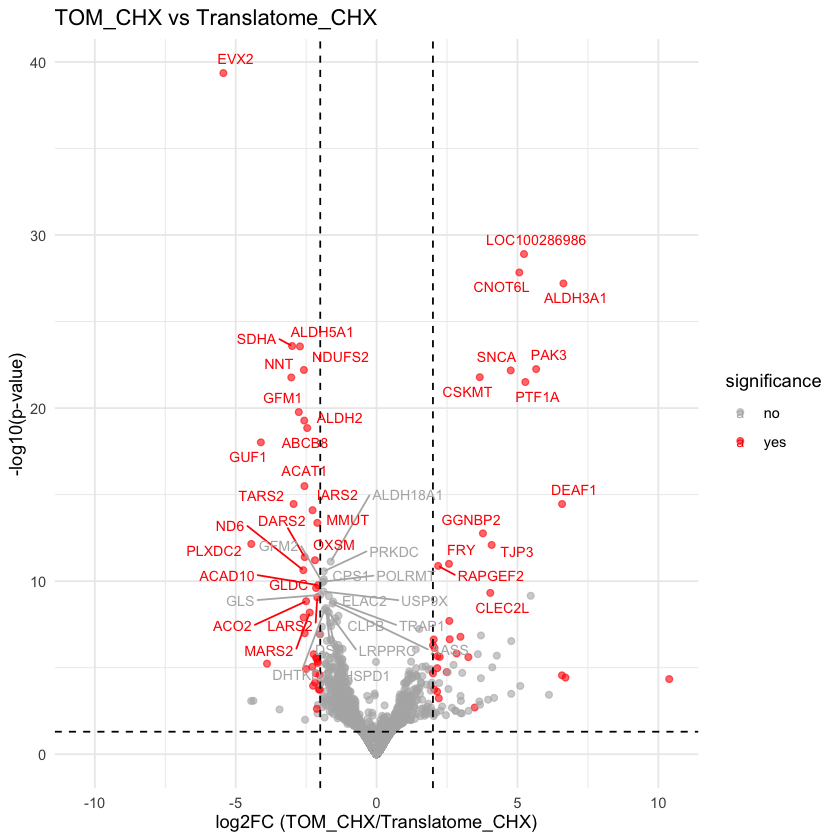

In [7]:
# determine symmetric range for log2FC axis
library(ggplot2)
library(ggrepel)
vol <- resDF%>%
     mutate(negLogP = -log10(pvalue),
          significance = ifelse(!is.na(padj) & padj < 0.05 & abs(log2FoldChange) >=2, "yes", "no"))

toplabels <- vol %>% filter(!is.na(padj)) %>% arrange(padj) %>% head(50)
lfc_max <- max(abs(vol$log2FoldChange), na.rm = TRUE)
volcano <- ggplot(vol, aes(x = log2FoldChange, 
                                 y = negLogP, 
                                 color = significance)) +
  geom_point(alpha = 0.6, size = 1.6) +

  # significant vs non-significant colors
  scale_color_manual(values = c("no" = "grey70", "yes" = "red")) +

  # dashed threshold lines
  geom_vline(xintercept = c(-2, 2), linetype = "dashed") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed") +

  # symmetric x-axis limits
  xlim(-lfc_max, lfc_max) +

  theme_minimal() +
  labs(
    title = "TOM_CHX vs Translatome_CHX",
    x = "log2FC (TOM_CHX/Translatome_CHX)",
    y = "-log10(p-value)"
  ) +

  # label top 50 most significant genes
  geom_text_repel(
    data = toplabels,
    aes(label = gene),
    size = 3,
    max.overlaps = 100,
    box.padding = 0.3
  )

volcano


In [71]:
ggsave( "DE_plot_trans_chx.png",volcano, width= 9.5, height = 7, dpi=300)

In [8]:
res_sig <- resDF %>% filter(!is.na(padj) & padj < 0.05 & abs(log2FoldChange) >=2) %>% arrange(padj)
# write.csv(res_sig, "/Users/shubham/labwork/yeast/chx_rep1/DE_significant_genes_translatome_CHX.csv", row.names = FALSE)


In [9]:
localization<- read.csv("all_genes_metadata_with_chx.csv")
res_sig <- res_sig %>%
  left_join(
    localization %>% select(gene, localization),
    by = "gene"
  )



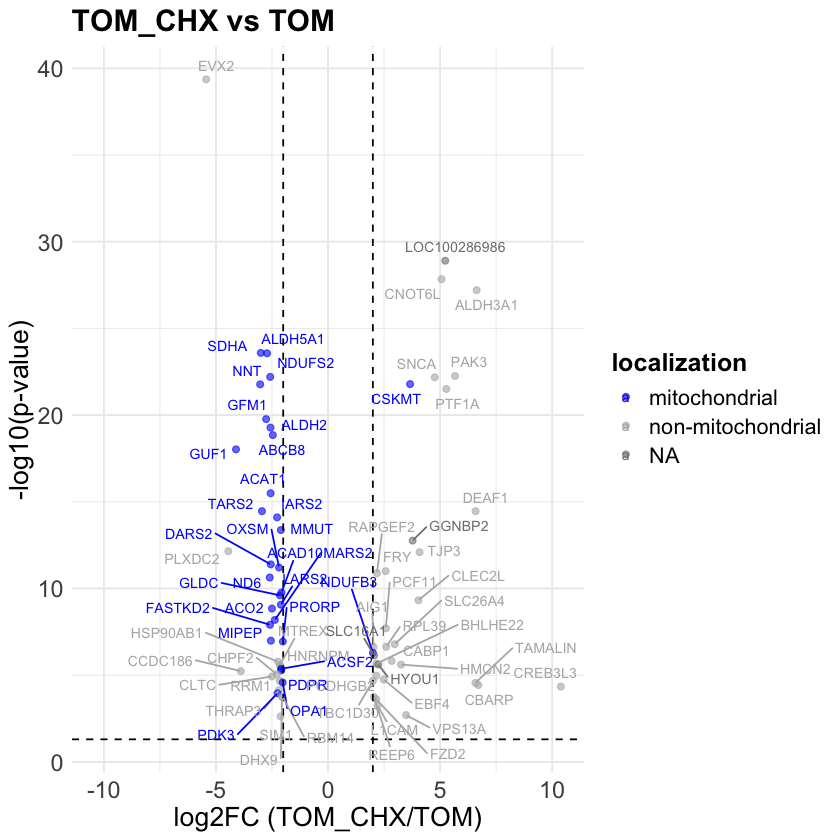

In [14]:
# determine symmetric range for log2FC axis
library(ggplot2)
library(ggrepel)

vol <- res_sig %>%
     mutate(
          negLogP = -log10(pvalue),
          localization = localization
     )

toplabels <- vol %>% filter(!is.na(padj)) %>% arrange(padj) %>% head(150)

lfc_max <- max(abs(vol$log2FoldChange), na.rm = TRUE)

volcano <- ggplot(vol, aes(x = log2FoldChange, 
                                 y = negLogP, 
                                 color = localization)) +
  geom_point(alpha = 0.6, size = 1.6) +

  # mitochondrial vs non-mitochondrial colors
  scale_color_manual(values = c(
    "mitochondrial" = "blue",
    "non-mitochondrial" = "gray70"
  )) +

  # dashed threshold lines
  geom_vline(xintercept = c(-2, 2), linetype = "dashed") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed") +

  # symmetric x-axis limits
  xlim(-lfc_max, lfc_max) +

  theme_minimal() +
  labs(
    title = "TOM_CHX vs TOM",
    x = "log2FC (TOM_CHX/TOM)",
    y = "-log10(p-value)"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(size = 18, face = "bold"),
    axis.title = element_text(size = 16),
    axis.text = element_text(size = 14),
    legend.title = element_text(size = 15, face = "bold"),
    legend.text = element_text(size = 13)
  ) +
  # label top 50 most significant genes
  geom_text_repel(
    data = toplabels,
    aes(label = gene),
    size = 3,
    max.overlaps = 100,
    box.padding = 0.3
  )

volcano

In [15]:
ggsave( "DE_plot_TOM_chx_localization.png",volcano, width= 9.5, height = 7, dpi=300)

In [13]:
write.csv(res_sig,"DE_CHX_localization.csv",row.names=FALSE)

In [16]:
dim(res_sig)
table(res_sig$localization)

[1] 73  7


    mitochondrial non-mitochondrial 
               29                40 